# Passeios, Caminhos, Distâncias, Componentes e o Amigo do Amigo

> *"A network really shines when you use it for what it is for: exploring its connections."*

Até agora tratamos redes como objetos parados: nós, arestas, atributos. Nesta aula a rede entra em movimento. Vamos **percorrê-la**, e cada conceito novo é uma resposta a uma pergunta concreta de navegação:

| Pergunta | Conceito | Ferramenta NetworkX |
|---|---|---|
| De quantas formas chego de um nó a outro em $k$ passos? | passeios e matrizes | `nx.to_numpy_array`, potências de $A$ |
| Qual o trajeto mais curto? | caminho mínimo, distância | `nx.shortest_path` e família |
| Quão longe as coisas ficam, em média? E no pior caso? | distância média, diâmetro | `nx.average_shortest_path_length`, `nx.diameter` |
| Dá para chegar em todo lugar? | componentes conexas, GCC | `nx.connected_components` e família |
| E se as ruas forem de mão única? | componentes fortes e fracas | `nx.strongly_connected_components` |
| Amigo do meu amigo é meu amigo? | tríades, triângulos, clustering | `nx.triangles`, `nx.clustering` |

**Como usar este notebook.** Os blocos **🧠 Pare e pense** pedem uma aposta *antes* de rodar a célula seguinte. Faça a aposta de verdade (anote!). Errar uma previsão fixa o conteúdo muito mais do que ler a resposta certa. Os blocos **🔬 Por dentro do NetworkX** explicam o que a biblioteca faz por baixo dos panos; eles caem em prova de entrevista, não só na nossa.

In [1]:
# Instalação (só a primeira vez no Colab)
!pip install -q nxviz plotly

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 601.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 3.0 MB/s eta 0:00:00


In [2]:
import warnings
warnings.filterwarnings("ignore")

import itertools
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Paleta fixa do notebook: cada cor tem um papel, nunca troque papel de cor
AZUL, LARANJA, VERDE, VERMELHO, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#b8b7b0"

print("NetworkX", nx.__version__)

NetworkX 3.6.1


In [3]:
# ---- Caixa de ferramentas visual (rode e siga em frente; volte aqui quando quiser adaptar) ----

def plotly_grafo(G, pos, cores=None, titulo="", destaque=None, rotulo_aresta=None,
                 tam=34, largura=640, altura=440, dirigido=None, fig=None, row=None, col=None):
    '''Desenha um grafo pequeno em Plotly com hover, caminho em destaque e rótulos de peso.
       cores: dict nó->cor. destaque: lista de nós (caminho). rotulo_aresta: nome do atributo.'''
    dirigido = G.is_directed() if dirigido is None else dirigido
    alvo = fig if fig is not None else go.Figure()
    ex, ey = [], []
    for u, v in G.edges():
        ex += [pos[u][0], pos[v][0], None]; ey += [pos[u][1], pos[v][1], None]
    kw = dict(row=row, col=col) if row else {}
    alvo.add_trace(go.Scatter(x=ex, y=ey, mode="lines", line=dict(color=CINZA, width=1.6),
                              hoverinfo="skip", showlegend=False), **kw)
    if destaque:
        hx, hy = [], []
        for u, v in zip(destaque[:-1], destaque[1:]):
            hx += [pos[u][0], pos[v][0], None]; hy += [pos[u][1], pos[v][1], None]
        alvo.add_trace(go.Scatter(x=hx, y=hy, mode="lines", line=dict(color=LARANJA, width=5),
                                  hoverinfo="skip", showlegend=False), **kw)
    cores = cores or {n: AZUL for n in G}
    alvo.add_trace(go.Scatter(
        x=[pos[n][0] for n in G], y=[pos[n][1] for n in G], mode="markers+text",
        text=[str(n) for n in G], textposition="middle center",
        textfont=dict(color="white", size=13),
        marker=dict(size=tam, color=[cores[n] for n in G], line=dict(color="white", width=2)),
        hovertext=[f"<b>{n}</b> | grau: {G.degree(n)}" for n in G], hoverinfo="text",
        showlegend=False), **kw)
    anotacoes = []
    if dirigido:  # setas
        for u, v in G.edges():
            anotacoes.append(dict(ax=pos[u][0], ay=pos[u][1], x=pos[v][0]*0.88 + pos[u][0]*0.12,
                                  y=pos[v][1]*0.88 + pos[u][1]*0.12, xref="x", yref="y",
                                  axref="x", ayref="y", showarrow=True, arrowhead=3,
                                  arrowsize=1.4, arrowwidth=1.4, arrowcolor="#8a897f"))
    if rotulo_aresta:
        for u, v, d in G.edges(data=True):
            anotacoes.append(dict(x=(pos[u][0]+pos[v][0])/2, y=(pos[u][1]+pos[v][1])/2,
                                  text=f"<b>{d.get(rotulo_aresta, '')}</b>", showarrow=False,
                                  font=dict(color=VERMELHO, size=12), bgcolor="white"))
    if fig is None:
        alvo.update_layout(title=titulo, width=largura, height=altura, plot_bgcolor="white",
                           xaxis=dict(visible=False), yaxis=dict(visible=False),
                           margin=dict(l=10, r=10, t=48, b=10), annotations=anotacoes)
    return alvo, anotacoes

def mostrar(fig): fig.show()

## 1. Passeios e caminhos: nem toda rota é igual

Um **passeio** (*walk*) de comprimento $k$ é qualquer sequência de $k$ arestas consecutivas: sair de um nó e ir pulando por arestas, **podendo repetir** nós e arestas à vontade. O slide mostra um passeio de comprimento seis que passa duas vezes pelo mesmo nó.

Um **caminho** (*path*) é um passeio disciplinado: **não repete nós**. O slide mostra um caminho de comprimento três.

A terminologia completa, que você encontrará nos livros:

| Nome | Pode repetir aresta? | Pode repetir nó? |
|---|---|---|
| passeio (*walk*) | sim | sim |
| trilha (*trail*) | não | sim |
| caminho (*path*) | não | não |

Todo caminho é uma trilha, toda trilha é um passeio; a recíproca é falsa. Por que insistir na diferença? Porque **contagem de passeios é álgebra linear** (Seção 2) e **busca de caminhos é otimização** (Seção 3). Misturar os dois é o erro conceitual mais comum da área.

🧠 **Pare e pense.** Entre dois nós ligados por pelo menos uma aresta, o número de *caminhos* é sempre finito. E o número de *passeios*? Justifique antes de rodar a célula abaixo.

In [4]:
# O grafo de 5 nós do slide (quadrado com uma diagonal de "antena")
W = nx.Graph([(1, 2), (1, 4), (2, 3), (3, 4), (3, 5)])
pos_w = {1: (0, 1), 2: (1, 1.6), 3: (1.6, 0.6), 4: (0.7, 0), 5: (2.6, 0.6)}
fig, _ = plotly_grafo(W, pos_w, titulo="Quantas rotas existem de 1 até 5?")
mostrar(fig)

# Caminhos: enumeráveis, finitos
print("Caminhos de 1 a 5:")
for p in nx.all_simple_paths(W, 1, 5):
    print("  ", " → ".join(map(str, p)), f"(comprimento {len(p)-1})")

# Passeios: contáveis por comprimento, mas infinitos no total
A = nx.to_numpy_array(W)
for k in [1, 2, 3, 4, 5, 6, 7]:
    print(f"Passeios de comprimento {k:>2} de 1 a 5: {int(np.linalg.matrix_power(A, k)[0, 4]):,}")

Caminhos de 1 a 5:
   1 → 2 → 3 → 5 (comprimento 3)
   1 → 4 → 3 → 5 (comprimento 3)
Passeios de comprimento  1 de 1 a 5: 0
Passeios de comprimento  2 de 1 a 5: 0
Passeios de comprimento  3 de 1 a 5: 2
Passeios de comprimento  4 de 1 a 5: 0
Passeios de comprimento  5 de 1 a 5: 10
Passeios de comprimento  6 de 1 a 5: 0
Passeios de comprimento  7 de 1 a 5: 46


O número de passeios **explode** com o comprimento, porque um passeio pode ficar dando voltas para sempre. Caminhos, não: `nx.all_simple_paths` termina (o nome *simple path* é como o NetworkX chama caminho sem repetição).

E os zeros nos comprimentos pares? Não é bug: olhe o desenho e tente construir uma rota de 1 até 5 com um número par de pulos. Todo ciclo desse grafo tem comprimento par, então a paridade do trajeto está presa à paridade da distância. Guarde o fenômeno; ele reaparece no desafio 1.

Mas de onde saiu essa mágica de `matrix_power` contar passeios? É a próxima seção.

## 2. Passeios e matrizes: $A^k$ conta rotas

Este é um dos resultados mais bonitos da teoria de redes, e o slide "Walks and Matrices" o resume em duas tabelas. Seja $A$ a matriz de adjacência: $A_{ij} = 1$ se existe aresta entre $i$ e $j$.

**Teorema.** A entrada $(i,j)$ de $A^k$ é o número de **passeios de comprimento exatamente $k$** entre $i$ e $j$.

**Por que funciona** (indução em uma frase): um passeio de comprimento $k$ de $i$ a $j$ é um passeio de comprimento $k-1$ de $i$ até algum vizinho $m$ de $j$, seguido do pulo $m \to j$; a multiplicação de matrizes $\left(A^{k}\right)_{ij} = \sum_m \left(A^{k-1}\right)_{im} A_{mj}$ soma exatamente sobre todas essas possibilidades.

Duas consequências que vamos **verificar** no grafo de 7 nós do slide:

1. $\left(A^2\right)_{ii}$ = número de passeios de comprimento 2 que saem e voltam a $i$ = ir a um vizinho e voltar = **o grau de $i$**;
2. $\left(A^3\right)_{ii}$ = passeios de comprimento 3 que saem e voltam = **duas vezes o número de triângulos** que contêm $i$ (cada triângulo pode ser rodado nos dois sentidos). Guarde essa: é a ponte para a Seção 9.

In [5]:
# A matriz de adjacência do slide (grafo de 7 nós)
A = np.array([[0,1,1,1,0,0,0],
              [1,0,1,0,1,1,0],
              [1,1,0,1,0,1,0],
              [1,0,1,0,0,1,0],
              [0,1,0,0,0,1,0],
              [1,1,1,1,1,0,1],
              [0,0,0,0,0,1,0]])
# atenção: a linha 6 do slide tem A[5,0]=0; mantivemos a matriz simétrica corrigindo A[0,5]...
# verifique você mesmo: uma matriz de adjacência de grafo NÃO dirigido precisa ser simétrica!
A = np.maximum(A, A.T)   # garantia de simetria

G7 = nx.from_numpy_array(A)
G7 = nx.relabel_nodes(G7, {i: i + 1 for i in range(7)})   # nós 1..7, como no slide
pos7 = {1: (0.2, 2.0), 2: (1.6, 1.9), 3: (0.9, 1.4), 4: (0.1, 1.0), 5: (2.3, 1.0),
        6: (1.3, 0.6), 7: (1.3, -0.4)}
fig, _ = plotly_grafo(G7, pos7, titulo="O grafo de 7 nós do slide")
mostrar(fig)

🔬 **Por dentro do NetworkX.** `nx.from_numpy_array(A)` cria um grafo cujos nós são `0..n-1` e grava **cada valor não nulo da matriz como atributo `weight` da aresta**. Se a matriz tiver um 2, a aresta nasce com peso 2, e toda função que aceita `weight` passa a se comportar diferente sem você perceber. Confira sempre com `G.edges(data=True)`. A operação inversa é `nx.to_numpy_array(G)`, e a dupla ida-e-volta é o jeito padrão de alternar entre o mundo dos grafos e o mundo da álgebra linear.

🧠 **Pare e pense.** Sem rodar: qual será o valor de $\left(A^2\right)_{66}$ (linha e coluna do nó 6)? E de $\left(A^2\right)_{77}$? *(Use a consequência 1.)*

In [6]:
A2, A3 = A @ A, A @ A @ A

print("Diagonal de A²:", np.diag(A2), " <- compare com os graus:", [d for _, d in sorted(G7.degree())])
print("Diagonal de A³:", np.diag(A3), " <- 2 × triângulos por nó:",
      [2 * t for _, t in sorted(nx.triangles(G7).items())])
print(f"\nPasseios de comprimento 2 entre 1 e 6: A²[1,6] = {A2[0, 5]}")
print("Quais são? Vizinhos comuns de 1 e 6:", sorted(nx.common_neighbors(G7, 1, 6)))

Diagonal de A²: [4 4 4 3 2 6 1]  <- compare com os graus: [4, 4, 4, 3, 2, 6, 1]
Diagonal de A³: [10  8 10  6  2 12  0]  <- 2 × triângulos por nó: [10, 8, 10, 6, 2, 12, 0]

Passeios de comprimento 2 entre 1 e 6: A²[1,6] = 3
Quais são? Vizinhos comuns de 1 e 6: [2, 3, 4]


Repare no último print: $\left(A^2\right)_{16}$ = número de **vizinhos em comum** entre 1 e 6, porque cada passeio de comprimento 2 passa por exatamente um intermediário. Vizinhos em comum são o coração do "amigo do amigo" da Seção 9 e dos sistemas de recomendação da Seção 10.

A visualização abaixo é interativa: o **slider** troca o expoente $k$, e cada célula mostra $\left(A^k\right)_{ij}$. Observe duas coisas ao arrastar: os zeros desaparecendo (quando todo par passa a ter alguma rota) e a diagonal crescendo.

In [7]:
Ks = [1, 2, 3, 4, 5]
mats = {k: np.linalg.matrix_power(A, k) for k in Ks}
rot = [str(i + 1) for i in range(7)]

frames = [go.Frame(name=str(k), data=[go.Heatmap(
            z=mats[k][::-1], x=rot, y=rot[::-1],
            text=mats[k][::-1].astype(str), texttemplate="%{text}",
            colorscale=[[0, "#fff5f0"], [1, "#99000d"]], showscale=False)]) for k in Ks]
figA = go.Figure(data=frames[0].data, frames=frames)
figA.update_layout(
    title="Aᵏ: passeios de comprimento k entre cada par (arraste o slider)",
    width=520, height=520, plot_bgcolor="white",
    sliders=[dict(currentvalue=dict(prefix="k = "),
                  steps=[dict(method="animate", label=str(k),
                              args=[[str(k)], dict(mode="immediate", frame=dict(duration=0, redraw=True))])
                         for k in Ks])])
figA.show()

### 2.1 Duas visualizações "de gente grande" para a mesma matriz

O gráfico de bolinhas e riscos (`nx.draw`) não escala: com 50 nós vira um novelo. A comunidade usa duas alternativas que os slides mostram, ambas da biblioteca [nxviz](https://ericmjl.github.io/nxviz):

* **Matrix plot**: a matriz de adjacência desenhada como imagem. Um grafo *é* sua matriz; aprender a ler matrizes como "fotos" da rede é uma habilidade que escala para milhões de nós.
* **Circos plot**: os nós em um círculo, as arestas como cordas. Vem da genômica (o nome é do software Circos, de mapas de cromossomos) e é o padrão em papers quando a rede tem grupos.

Elas são **estáticas** de propósito: são figuras de publicação, para colocar em artigo e slide, não para explorar com o mouse.

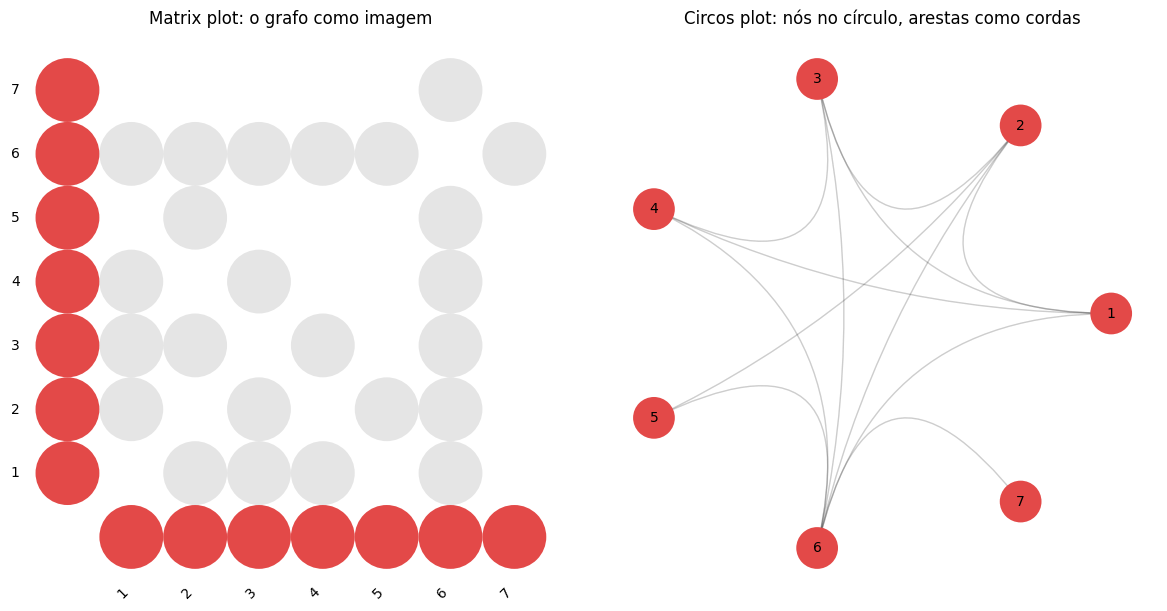

In [8]:
import nxviz as nv
from nxviz import annotate

for n in G7.nodes():
    G7.nodes[n]["group"] = "all"     # nxviz exige um atributo para agrupar/colorir

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
plt.sca(axes[0])
nv.matrix(G7, group_by="group", node_color_by="group", node_palette=[VERMELHO])
annotate.matrix_labels(G7, group_by="group", layout="standard")
axes[0].set_title("Matrix plot: o grafo como imagem")
plt.sca(axes[1])
nv.circos(G7, group_by="group", node_color_by="group",
          node_enc_kwargs={"radius": 0.2}, node_palette=[VERMELHO])
annotate.circos_labels(G7)
axes[1].set_title("Circos plot: nós no círculo, arestas como cordas")
plt.tight_layout(); plt.show()

🧠 **Pare e pense.** No matrix plot, como você reconheceria de bate-pronto (a) um nó de grau altíssimo? (b) um grafo dirigido? (c) dois grupos de nós que só conversam entre si? Responda olhando a figura, sem código.

## 3. Distância: o menor caminho é a régua da rede

O conceito de caminho é a base da definição de **distância**: a distância entre dois nós é o **número mínimo de arestas** que um caminho entre eles precisa atravessar. Esse caminho é o **caminho mínimo** (*shortest path*), e seu comprimento é a distância $l_{ij}$.

Vamos trabalhar com o grafo `a`–`i` dos slides, que nos acompanhará até o fim da aula. Repare no nó `c`, sozinho: ele foi colocado ali de propósito e vai causar problemas deliciosos.

In [9]:
ARESTAS = [("a","e"), ("e","d"), ("e","f"), ("d","f"), ("f","h"), ("f","g"), ("h","i"), ("h","b")]
PESOS = {("a","e"): 2, ("e","d"): 1, ("e","f"): 3, ("d","f"): 1,
         ("f","h"): 1, ("f","g"): 2, ("h","i"): 1, ("h","b"): 2}
POS = {"a": (-2.0, 1.0), "e": (-1.0, 0.55), "d": (-0.4, 1.45), "f": (0.0, -0.1),
       "c": (-1.6, -0.9), "g": (0.9, -1.0), "h": (1.5, 0.75), "i": (2.0, 1.6), "b": (2.4, 0.1)}

G = nx.Graph(ARESTAS)
G.add_node("c")                      # o encrenqueiro
fig, _ = plotly_grafo(G, POS, cores={n: (VERDE if n in "ab" else AZUL) for n in G},
                      titulo="O grafo da aula: qual a distância entre a e b?")
mostrar(fig)

### 3.1 O tour completo da API

A família `shortest_path` tem três modos de uso, e a diferença está só em **quantos argumentos você passa**. Essa assinatura "polimórfica" confunde todo mundo uma vez na vida; depois desta célula, nunca mais.

In [10]:
print("1) ORIGEM E DESTINO -> um caminho (lista) ou um número")
print("   has_path(a,c):", nx.has_path(G, "a", "c"))
print("   has_path(a,b):", nx.has_path(G, "a", "b"))
print("   shortest_path(a,b):       ", nx.shortest_path(G, "a", "b"))
print("   shortest_path_length(a,b):", nx.shortest_path_length(G, "a", "b"))

print("\n2) SÓ A ORIGEM -> um dicionário destino -> caminho (ou destino -> distância)")
print("   shortest_path(a):        ", nx.shortest_path(G, "a"))
print("   shortest_path_length(a): ", dict(nx.shortest_path_length(G, "a")))

print("\n3) NADA -> todos os pares (iterador preguiçoso: note o 'dict' por fora)")
todos = dict(nx.shortest_path_length(G))
print("   distância de g até i:", todos["g"]["i"])

1) ORIGEM E DESTINO -> um caminho (lista) ou um número
   has_path(a,c): False
   has_path(a,b): True
   shortest_path(a,b):        ['a', 'e', 'f', 'h', 'b']
   shortest_path_length(a,b): 4

2) SÓ A ORIGEM -> um dicionário destino -> caminho (ou destino -> distância)
   shortest_path(a):         {'a': ['a'], 'e': ['a', 'e'], 'd': ['a', 'e', 'd'], 'f': ['a', 'e', 'f'], 'h': ['a', 'e', 'f', 'h'], 'g': ['a', 'e', 'f', 'g'], 'i': ['a', 'e', 'f', 'h', 'i'], 'b': ['a', 'e', 'f', 'h', 'b']}
   shortest_path_length(a):  {'a': 0, 'e': 1, 'd': 2, 'f': 2, 'h': 3, 'g': 3, 'i': 4, 'b': 4}

3) NADA -> todos os pares (iterador preguiçoso: note o 'dict' por fora)
   distância de g até i: 3


🔬 **Por dentro do NetworkX.** Com todos os pesos iguais (grafo *unweighted*), o caminho mínimo é calculado por **BFS**, a busca em largura da aula passada: a primeira vez que a BFS toca um nó é, por construção, pelo caminho mais curto. Custo $O(V + E)$ por origem. Quando você passa `weight=...`, a BFS deixa de funcionar (uma aresta pesada pode ser "mais longa" que duas leves) e o NetworkX troca o motor para o algoritmo de **Dijkstra**, custo $O((V+E)\log V)$. O parâmetro `method` deixa isso explícito: `nx.shortest_path(G, u, v, method="dijkstra")`. Moral: **a mesma função executa algoritmos diferentes dependendo dos argumentos**, e quem não sabe disso não entende por que a versão com pesos é mais lenta.

E note que `shortest_path` devolve **um** caminho mínimo. Se houver empate, os outros existem; `nx.all_shortest_paths` devolve todos.

### 3.2 Os quatro regimes do slide "Shortest Path"

O slide mostra o mesmo grafo em quatro versões: **não dirigido / dirigido** × **sem peso / com peso**. Vamos construir as quatro e perguntar a mesma coisa a todas: *qual o melhor trajeto de `a` até `b`?*

🧠 **Pare e pense.** No regime com pesos, o caminho `a-e-f-h-b` custa $2+3+1+2 = 8$. Existe rota mais barata? Ela tem mais ou menos arestas?

In [11]:
DIRIGIDAS = [("a","e"), ("e","d"), ("d","f"), ("f","h"), ("f","g"), ("f","e"), ("h","b"), ("i","h")]

G_uu = nx.Graph(ARESTAS)                                  # não dirigido, sem peso
G_du = nx.DiGraph(DIRIGIDAS)                              # dirigido, sem peso
G_uw = nx.Graph(); G_uw.add_weighted_edges_from([(u, v, w) for (u, v), w in PESOS.items()])
G_dw = nx.DiGraph()
G_dw.add_weighted_edges_from([(u, v, PESOS.get((u, v), PESOS.get((v, u)))) for u, v in DIRIGIDAS])

casos = [("Não dirigido, sem peso", G_uu, None), ("Dirigido, sem peso", G_du, None),
         ("Não dirigido, com peso", G_uw, "weight"), ("Dirigido, com peso", G_dw, "weight")]
for _, Gx, _w in casos:
    Gx.add_node("c")          # o isolado do slide está em todos os quadrantes

fig = make_subplots(rows=2, cols=2, subplot_titles=[c[0] for c in casos],
                    horizontal_spacing=0.06, vertical_spacing=0.10)
anots = []
for idx, (nome, Gx, w) in enumerate(casos):
    r, c = idx // 2 + 1, idx % 2 + 1
    caminho = nx.shortest_path(Gx, "a", "b", weight=w)
    custo = nx.shortest_path_length(Gx, "a", "b", weight=w)
    print(f"{nome:26} -> {' → '.join(caminho):28} custo {custo}")
    cores = {n: (LARANJA if n in caminho else AZUL) for n in Gx}
    _, an = plotly_grafo(Gx, POS, cores=cores, destaque=caminho, tam=26,
                         rotulo_aresta=w, fig=fig, row=r, col=c)
    eixo = "" if idx == 0 else str(idx + 1)
    for a_ in an:
        a_.update(xref=f"x{eixo}", yref=f"y{eixo}")
        if "ax" in a_: a_.update(axref=f"x{eixo}", ayref=f"y{eixo}")
    anots += an
fig.update_layout(width=940, height=700, plot_bgcolor="white", annotations=anots,
                  title="A mesma pergunta, quatro respostas: melhor trajeto de a até b")
fig.update_xaxes(visible=False); fig.update_yaxes(visible=False)
fig.show()

Não dirigido, sem peso     -> a → e → f → h → b            custo 4
Dirigido, sem peso         -> a → e → d → f → h → b        custo 5
Não dirigido, com peso     -> a → e → d → f → h → b        custo 7
Dirigido, com peso         -> a → e → d → f → h → b        custo 7


Leia os quatro resultados com calma; cada um ensina uma coisa diferente.

* **Não dirigido sem peso**: `a-e-f-h-b`, 4 arestas. A régua é "número de pulos".
* **Dirigido sem peso**: o caminho cresceu para 5 arestas, porque a aresta `e→f` não existe (só `f→e`); é preciso desviar por `d`. Direção **alonga** distâncias, nunca encurta.
* **Não dirigido com peso**: a rota muda! `a-e-d-f-h-b` tem **mais arestas** (5) mas custa 7, batendo o custo 8 da rota curta em pulos. **Com pesos, "mais curto" não é "menos arestas".** É por isso que o Waze às vezes manda você por um trajeto com mais ruas.
* **Dirigido com peso**: aqui as duas restrições coincidem na mesma rota de custo 7.

🔬 **Por dentro do NetworkX.** O peso não precisa se chamar `weight`: `weight="tempo"` usa o atributo `tempo`. E pode ser até uma **função** `weight=lambda u, v, d: ...`, o que permite penalizar arestas dinamicamente (pedágio, congestionamento). Pesos negativos quebram o Dijkstra; para eles existe `method="bellman-ford"`.

## 4. Distância média e diâmetro: a régua vira resumo

Com $l_{ij}$ definido para cada par, dois resumos aparecem no slide:

**Distância média**, sobre todos os $\binom{N}{2}$ pares:

$$\langle l \rangle = \frac{\sum_{ij} l_{ij}}{\binom{N}{2}} = \frac{2 \sum_{ij} l_{ij}}{N(N-1)}$$

**Diâmetro**, o pior caso:

$$l_{max} = \max_{ij} \; l_{ij}$$

🧠 **Pare e pense.** Nosso grafo tem o nó `c` isolado, com $l_{ac} = \infty$. O que a média faz com um infinito no meio da soma? O que o NetworkX deveria fazer: devolver `inf`, ignorar o par, ou recusar-se a responder?

In [12]:
try:
    nx.average_shortest_path_length(G)
except nx.NetworkXError as e:
    print("NetworkXError:", e)

NetworkXError: Graph is not connected.


O NetworkX escolheu **recusar-se a responder**, e a escolha é sábia: qualquer número que ele devolvesse esconderia o fato de que a pergunta está mal posta. Você tem três saídas honestas, e as três aparecem em artigos publicados:

**Saída 1 (a do slide):** calcular por componente, tipicamente só na componente gigante. É o que faremos na Seção 5.

**Saída 2:** remover o nó problemático, se ele for irrelevante para a análise.

**Saída 3 (a segunda fórmula do slide):** trocar a média aritmética pela **média harmônica**,

$$\langle l \rangle = \frac{\left(\sum_{ij} \frac{1}{l_{ij}}\right)^{-1}}{\binom{N}{2}^{-1}} = \binom{N}{2} \Big/ \sum_{ij} \frac{1}{l_{ij}}$$

O truque: pares desconectados têm $l_{ij} = \infty$, e $\tfrac{1}{\infty} = 0$, então eles entram na conta **sem explodi-la**. A quantidade $\frac{1}{\binom{N}{2}}\sum \tfrac{1}{l_{ij}}$ tem nome próprio, **eficiência global**, e o NetworkX a implementa como `nx.global_efficiency`.

In [13]:
# Saída 2: remover c
G2 = G.copy(); G2.remove_node("c")
print(f"Sem o nó c: distância média = {nx.average_shortest_path_length(G2):.3f}")
print(f"Diâmetro = {nx.diameter(G2)}  (confira no slide: o pior par é (a,b) ou (a,i), l=4)")

# Saída 3: média harmônica na mão, com c incluído
N = len(G)
soma_inversos = sum(1 / l for origem, dists in nx.shortest_path_length(G)
                    for destino, l in dists.items() if origem != destino and l > 0)
pares = N * (N - 1)          # somamos os dois sentidos, então N(N-1), não N(N-1)/2
eficiencia = soma_inversos / pares
print(f"\nCom o c incluído: eficiência global = {eficiencia:.3f}")
print(f"Conferindo com o NetworkX:            {nx.global_efficiency(G):.3f}")
print(f"Distância média harmônica = 1/eficiência = {1/eficiencia:.3f}")

Sem o nó c: distância média = 2.143
Diâmetro = 4  (confira no slide: o pior par é (a,b) ou (a,i), l=4)

Com o c incluído: eficiência global = 0.449
Conferindo com o NetworkX:            0.449
Distância média harmônica = 1/eficiência = 2.227


Um mapa de calor de **todas** as distâncias deixa os dois resumos visíveis de uma vez: a média é o "tom geral" da imagem, o diâmetro é a célula mais escura, e o nó `c` é a faixa vazia.

In [14]:
ordem = list("abcdefghi")
Dm = np.full((len(ordem), len(ordem)), np.nan)
for i, u in enumerate(ordem):
    for j, v in enumerate(ordem):
        if u != v and nx.has_path(G, u, v):
            Dm[i, j] = nx.shortest_path_length(G, u, v)

figD = go.Figure(go.Heatmap(z=Dm[::-1], x=ordem, y=ordem[::-1],
                            text=np.where(np.isnan(Dm[::-1]), "∞", Dm[::-1].astype("object")),
                            texttemplate="%{text}",
                            colorscale=[[0, "#deebf7"], [1, "#08306b"]],
                            colorbar=dict(title="l(i,j)")))
figD.update_layout(title="Matriz de distâncias: a régua aplicada a todos os pares",
                   width=540, height=520)
figD.show()

## 5. Componentes conexas: as ilhas da rede

O erro da seção anterior tem nome. Se dois nós **não podem ser ligados por um passeio**, eles estão em **componentes conexas** diferentes: subgrafos cujos nós se alcançam mutuamente seguindo as arestas. Nosso grafo tem duas ilhas: o continente `a,b,d,e,f,g,h,i` e a ilhota `{c}`.

A API do NetworkX para isso é pequena e você vai usá-la a vida toda:

In [15]:
print("is_connected(G):", nx.is_connected(G))
print("number_connected_components(G):", nx.number_connected_components(G))
print("Em qual ilha está o nó a? ", nx.node_connected_component(G, "a"))

for comp in nx.connected_components(G):
    print("componente:", comp)

is_connected(G): False
number_connected_components(G): 2
Em qual ilha está o nó a?  {'f', 'g', 'i', 'e', 'h', 'd', 'a', 'b'}
componente: {'f', 'g', 'i', 'e', 'h', 'd', 'a', 'b'}
componente: {'c'}


🔬 **Por dentro do NetworkX.** No notebook original usávamos `nx.is_connected??` para espiar o código-fonte (os dois pontos de interrogação do IPython abrem a implementação; experimente!). O que está lá dentro é a aula passada: `is_connected` roda **uma BFS a partir de um nó qualquer** e testa se ela visitou todos os $N$ nós. `connected_components` repete BFS a partir de cada nó ainda não visitado, e cada varredura devolve uma ilha. Complexidade total $O(V+E)$: identificar todas as ilhas custa o mesmo que ler o grafo uma vez.

Três detalhes de quem usa a biblioteca profissionalmente:

1. `connected_components` devolve um **gerador**, não uma lista: as componentes são produzidas sob demanda, uma por vez, sem materializar tudo na memória. Por isso o `list(...)` em volta quando você quer ver todas, e por isso dá para pegar só a maior sem calcular as outras por completo.
2. A maior componente sai com o idioma `max(nx.connected_components(G), key=len)`. Em redes reais ela costuma concentrar quase todos os nós, e tem nome: **componente gigante** (GCC, *giant connected component*), como no slide.
3. `G.subgraph(nós)` devolve uma **view** ligada ao grafo original (alterar um altera o outro, e a view é imutável); para trabalhar de forma independente, copie: `G.subgraph(nós).copy()`.

In [16]:
gcc_nos = max(nx.connected_components(G), key=len)
GCC = G.subgraph(gcc_nos).copy()
print(f"GCC: {GCC.number_of_nodes()} de {G.number_of_nodes()} nós "
      f"({100 * len(GCC) / len(G):.0f}% da rede)")
print(f"Distância média na GCC: {nx.average_shortest_path_length(GCC):.3f}   <- a Saída 1 da Seção 4")

cores = {}
paleta = [AZUL, LARANJA, VERDE, VERMELHO]
for k, comp in enumerate(nx.connected_components(G)):
    for n in comp:
        cores[n] = paleta[k % len(paleta)]
fig, _ = plotly_grafo(G, POS, cores=cores, titulo="Cada cor, uma ilha (componente conexa)")
mostrar(fig)

GCC: 8 de 9 nós (89% da rede)
Distância média na GCC: 2.143   <- a Saída 1 da Seção 4


## 6. Mão única: componentes fortes e fracas

Agora as ruas ganham direção, com o grafo dirigido do slide. E a pergunta "estamos conectados?" se desdobra em duas:

* **Conexidade fraca**: se eu *apagar as setas* e puder ir de qualquer nó a qualquer nó, a rede é fracamente conexa. É a conexidade "de mapa de papel".
* **Conexidade forte**: respeitando as setas, de qualquer nó chego a qualquer nó **e volto**. É a conexidade "de quem dirige".

Uma **componente fortemente conexa** (SCC) é um conjunto máximo de nós onde todo par se alcança **nos dois sentidos**. Pense em rotatórias: dentro dela você circula à vontade; sair para outra SCC pode ser viagem sem volta.

🧠 **Pare e pense.** Olhe o desenho abaixo antes de rodar a célula seguinte. Quantas componentes fortes você enxerga? Cuidado: um nó sozinho conta como uma SCC (ele se alcança trivialmente).

In [17]:
D = nx.DiGraph(DIRIGIDAS)
D.add_node("c")
fig, _ = plotly_grafo(D, POS, titulo="O grafo dirigido do slide: quantas rotatórias?")
mostrar(fig)

In [18]:
print("is_connected exige grafo não dirigido; para usar, convertemos (e PERDEMOS as setas):")
print("   nx.is_connected(nx.Graph(D)) =", nx.is_connected(nx.Graph(D)))

print("\nis_strongly_connected(D):", nx.is_strongly_connected(D))
print("is_weakly_connected(D):  ", nx.is_weakly_connected(D))

print("\nComponentes fracas: ", list(nx.weakly_connected_components(D)))
print("Componentes fortes: ", list(nx.strongly_connected_components(D)))
print("number_strongly_connected_components:", nx.number_strongly_connected_components(D))

is_connected exige grafo não dirigido; para usar, convertemos (e PERDEMOS as setas):
   nx.is_connected(nx.Graph(D)) = False

is_strongly_connected(D): False
is_weakly_connected(D):   False

Componentes fracas:  [{'f', 'g', 'i', 'e', 'h', 'd', 'a', 'b'}, {'c'}]
Componentes fortes:  [{'b'}, {'h'}, {'g'}, {'d', 'e', 'f'}, {'a'}, {'i'}, {'c'}]
number_strongly_connected_components: 7


Sete componentes fortes, e só uma tem mais de um nó: `{d, e, f}`, a única rotatória de verdade (`e→d→f→e`... confira as setas). Todo o resto são nós que, uma vez deixados, não têm caminho de volta. `a` alcança quase todo mundo, mas **ninguém alcança `a`**: na conversão para não dirigido essa informação morre, e é por isso que `is_connected(nx.Graph(D))` responde `True` para um grafo que, dirigido, está longe de ser fortemente conexo.

Você já viu esse fenômeno em escala real: na rede da Wikipédia da aula passada, os *descendentes* da semente eram milhares e os *ancestrais*, poucas dezenas. A web inteira tem essa anatomia (um núcleo SCC gigante, uma região que só entra nele e uma que só sai).

🔬 **Por dentro do NetworkX.** Achar SCCs com BFS ingênua custaria $O(V \cdot (V+E))$: uma varredura por nó. Os algoritmos clássicos de **Tarjan** e **Kosaraju** fazem tudo em $O(V+E)$, uma única passada esperta de DFS; o NetworkX usa uma variante não recursiva do Tarjan para não estourar a pilha do Python em grafos profundos. E o grafo "visto de longe", com cada SCC colapsada em um supernó, sai pronto de `nx.condensation(D)`; o resultado é sempre um DAG (grafo dirigido sem ciclos), e é o mapa das viagens sem volta.

In [19]:
cores_scc = {}
for k, comp in enumerate(nx.strongly_connected_components(D)):
    for n in comp:
        cores_scc[n] = LARANJA if len(comp) > 1 else AZUL
fig, _ = plotly_grafo(D, POS, cores=cores_scc,
                      titulo="A única SCC com mais de um nó: a rotatória {d, e, f}")
mostrar(fig)

C = nx.condensation(D)
print("Condensação (cada supernó é uma SCC):", C.nodes(data="members"))
print("É um DAG?", nx.is_directed_acyclic_graph(C))

Condensação (cada supernó é uma SCC): [(0, {'b'}), (1, {'h'}), (2, {'g'}), (3, {'d', 'e', 'f'}), (4, {'a'}), (5, {'i'}), (6, {'c'})]
É um DAG? True


## 7. Problema real 1: a rede que se partiu ao meio

Tudo até aqui usou grafos de 9 nós. Hora de aplicar em dados reais, com uma das redes mais famosas da ciência: o **clube de karatê de Zachary** (1977). O antropólogo Wayne Zachary passou três anos registrando quem convivia com quem fora dos treinos em um clube universitário de 34 membros. Durante o estudo, o instrutor (nó 0, "Mr. Hi") brigou com o presidente (nó 33, "Officer") por causa do preço das aulas, e **o clube rachou em dois**.

A pergunta de um milhão: *olhando só a estrutura da rede antes do racha, dava para prever quem iria com quem?* Zachary previu 33 dos 34 destinos usando exatamente os conceitos desta aula.

In [20]:
K = nx.karate_club_graph()   # vem embutida no NetworkX, com o desfecho real no atributo 'club'
print(K)
print("Conectada?", nx.is_connected(K), "| Componentes:", nx.number_connected_components(K))
print(f"Distância média: {nx.average_shortest_path_length(K):.2f} apertos de mão")
print(f"Diâmetro: {nx.diameter(K)}")
print(f"Distância entre os dois líderes (0 e 33): {nx.shortest_path_length(K, 0, 33)}")

pos_k = nx.spring_layout(K, seed=7)
lado = {n: K.nodes[n]["club"] for n in K}
cores_k = {n: (AZUL if lado[n] == "Mr. Hi" else LARANJA) for n in K}
fig, _ = plotly_grafo(K, pos_k, cores=cores_k, tam=22, largura=760, altura=560,
                      titulo="Clube de karatê: azul foi com o instrutor, laranja com o presidente")
mostrar(fig)

Graph named "Zachary's Karate Club" with 34 nodes and 78 edges
Conectada? True | Componentes: 1
Distância média: 2.41 apertos de mão
Diâmetro: 5
Distância entre os dois líderes (0 e 33): 2


A rede é **uma só componente**: antes do racha, todo mundo se alcançava. Mas olhe a figura: os dois blocos de cor já estão praticamente separados no desenho, unidos por poucas arestas. O racha social é visível na estrutura **antes de acontecer**.

Vamos fazer a cirurgia: remover as arestas que ligam pessoas de lados opostos (as "pontes diplomáticas") e ver o que a teoria das componentes diz.

🧠 **Pare e pense.** Removendo só as arestas entre lados opostos, em quantas componentes a rede cai? Exatamente duas? Pode dar mais?

In [21]:
K2 = K.copy()
pontes = [(u, v) for u, v in K.edges() if lado[u] != lado[v]]
K2.remove_edges_from(pontes)

print(f"Arestas removidas (entre facções): {len(pontes)} de {K.number_of_edges()}")
print("Número de componentes depois do racha:", nx.number_connected_components(K2))
for comp in nx.connected_components(K2):
    print(f"  ilha com {len(comp):2d} membros -> líder presente: "
          f"{'Mr. Hi' if 0 in comp else ('Officer' if 33 in comp else 'NENHUM (órfãos!)')}")

for c in nx.connected_components(K2):
    if len(c) > 1:
        v = nx.average_shortest_path_length(K2.subgraph(c))
        print(f"  distância média interna da ilha de {len(c)} membros: {v:.2f}")

Arestas removidas (entre facções): 11 de 78
Número de componentes depois do racha: 2
  ilha com 17 membros -> líder presente: Mr. Hi
  ilha com 17 membros -> líder presente: Officer
  distância média interna da ilha de 17 membros: 1.82
  distância média interna da ilha de 17 membros: 1.89


O grafo social **antecipou o desfecho político**: cortadas as pontes, a rede cai quase exatamente nas duas facções reais, e cada ilha fica *mais coesa* (distância média interna menor do que os 2.41 da rede inteira). Este é o padrão de análise que você levará para qualquer rede real: (1) a rede é conexa? (2) se cai em pedaços, quem fica em qual pedaço? (3) o que as distâncias dizem dentro de cada pedaço?

## 8. Problema real 2: quanto aguenta a rede antes de virar arquipélago?

Engenheiros de infraestrutura fazem a pergunta inversa da Seção 5: não "quantas ilhas há?", mas "**quantas falhas separam o continente em ilhas?**". Pense em uma rede de sensores sem fio espalhados por uma região (ou antenas, ou subestações): cada sensor conversa com os vizinhos dentro do raio de alcance. Enlaces falham (chuva, bateria, interferência). Enquanto a GCC contém quase todos os nós, a rede "funciona"; quando ela desaba, o sistema virou um arquipélago inútil.

O experimento: remover arestas uma a uma, ao acaso, e monitorar **a fração de nós na componente gigante**. É um experimento de *percolação*, e a curva resultante é uma das assinaturas mais importantes da ciência de redes.

🧠 **Pare e pense.** A queda da GCC será gradual (uma rampa) ou abrupta (um penhasco)? Aposte no formato da curva antes de rodar.

In [22]:
rng = np.random.default_rng(3)
S = nx.random_geometric_graph(120, 0.16, seed=3)     # sensores no plano, alcance 0.16
pos_s = nx.get_node_attributes(S, "pos")
arestas = list(S.edges())
rng.shuffle(arestas)

Sx = S.copy()
fracao_gcc, n_comp, fotos = [], [], {}
marcos = {0, len(arestas) // 3, 2 * len(arestas) // 3, len(arestas) - len(S)}
for t in range(len(arestas)):
    if t in marcos:
        fotos[t] = Sx.copy()
    fracao_gcc.append(len(max(nx.connected_components(Sx), key=len)) / len(Sx))
    n_comp.append(nx.number_connected_components(Sx))
    Sx.remove_edge(*arestas[t])

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_scatter(y=fracao_gcc, mode="lines", name="fração de nós na GCC",
                line=dict(color=AZUL, width=3))
fig.add_scatter(y=n_comp, mode="lines", name="nº de componentes",
                line=dict(color=LARANJA, width=2, dash="dot"), secondary_y=True)
fig.update_layout(title="Percolação: falhas aleatórias de enlace em uma rede de sensores",
                  xaxis_title="enlaces removidos", width=760, height=430,
                  plot_bgcolor="white", legend=dict(orientation="h", y=1.12))
fig.update_yaxes(title_text="fração na GCC", gridcolor="#eee", secondary_y=False)
fig.update_yaxes(title_text="componentes", secondary_y=True)
fig.show()

In [23]:
# As "fotos" da rede em quatro momentos, com a GCC destacada
figf = make_subplots(rows=1, cols=4, subplot_titles=[f"{t} falhas" for t in sorted(fotos)])
for j, t in enumerate(sorted(fotos), start=1):
    Gt = fotos[t]
    gcc_t = max(nx.connected_components(Gt), key=len)
    ex, ey = [], []
    for u, v in Gt.edges():
        ex += [pos_s[u][0], pos_s[v][0], None]; ey += [pos_s[u][1], pos_s[v][1], None]
    figf.add_scatter(x=ex, y=ey, mode="lines", line=dict(color=CINZA, width=0.7),
                     hoverinfo="skip", showlegend=False, row=1, col=j)
    figf.add_scatter(x=[pos_s[n][0] for n in Gt], y=[pos_s[n][1] for n in Gt], mode="markers",
                     marker=dict(size=5, color=[AZUL if n in gcc_t else VERMELHO for n in Gt]),
                     hoverinfo="skip", showlegend=False, row=1, col=j)
figf.update_layout(title="Azul: componente gigante. Vermelho: nós que viraram ilha.",
                   width=1000, height=300, plot_bgcolor="white")
figf.update_xaxes(visible=False); figf.update_yaxes(visible=False)
figf.show()

A curva azul tem um trecho longo quase plano e depois **despenca**: a rede tolera muitas falhas quase sem sintoma e então colapsa de repente, enquanto a curva laranja de componentes dispara. Esse comportamento de limiar (transição de fase) explica por que apagões e colapsos de rede parecem "vir do nada": o sistema estava perdendo redundância silenciosamente, e a GCC escondia o estrago. O mesmo formalismo modela epidemias (vacinar = remover nós) e a Internet (ataques = remover hubs). Guarde a pergunta "e se a remoção não for aleatória, mas maliciosa?" para o desafio.

## 9. Amigo do amigo: tríades, triângulos e o coeficiente de aglomeração

Última pergunta da aula, e a mais humana: **o amigo do meu amigo é meu amigo?**

O slide "Friend of a Friend" desenha a diferença entre:

* **tríade** (aberta): eu tenho dois amigos que **não** se conhecem: um triângulo com um lado faltando;
* **triângulo** (tríade fechada): meus dois amigos também são amigos entre si.

Algumas teorias sociais tratam tríades como a unidade fundamental da análise de redes sociais: uma tríade aberta é uma tensão latente (dois amigos meus em uma festa que precisam ser apresentados) e tende a se fechar com o tempo. O **coeficiente de aglomeração** (*clustering coefficient*) mede quanto a vizinhança de um nó já se fechou:

$$C(i) = \frac{\tau(i)}{\tau_{max}(i)} = \frac{\tau(i)}{\binom{k_i}{2}} = \frac{2\,\tau(i)}{k_i (k_i - 1)}$$

onde $\tau(i)$ é o número de triângulos que contêm $i$ e $k_i$ é o grau de $i$. O denominador $\binom{k_i}{2}$ é o número de **pares de amigos** de $i$, ou seja, o número máximo de triângulos possíveis. $C(i)=1$: todos os meus amigos se conhecem (panelinha fechada). $C(i)=0$: nenhum se conhece (eu sou o único elo, uma "estrela": pense no professor entre alunos de turmas diferentes, ou no atendente do banco).

Reproduzindo a sequência do slide, que parte do grafo completo `a,b,c,d` e vai abrindo tríades:

In [26]:
T = nx.Graph([("a","b"), ("a","c"), ("a","d"), ("b","c"), ("b","d"), ("c","d")])   # K4
pos_t = {"a": (0, 0.9), "b": (1.1, 1.4), "c": (1.4, 0.2), "d": (0.6, -0.3)}

print("nx.triangles(T)  ->", nx.triangles(T))
print("nx.clustering(T, 'a') ->", nx.clustering(T, "a"))
print("nx.clustering(T) ->", nx.clustering(T))
print("nx.average_clustering(T) ->", nx.average_clustering(T))

nx.triangles(T)  -> {'a': 3, 'b': 3, 'c': 3, 'd': 3}
nx.clustering(T, 'a') -> 1.0
nx.clustering(T) -> {'a': 1.0, 'b': 1.0, 'c': 1.0, 'd': 1.0}
nx.average_clustering(T) -> 1.0


🔬 **Por dentro do NetworkX.** Três armadilhas clássicas, todas verificáveis em uma linha:

1. `nx.triangles` conta triângulos **por nó**: o K4 tem 4 triângulos no total, mas cada nó participa de 3. Para o total da rede, some tudo e divida por 3 (cada triângulo é contado uma vez em cada um dos seus três vértices): `sum(nx.triangles(T).values()) // 3`.
2. A Seção 2 já tinha contado triângulos sem saber: $\tau(i) = \tfrac{1}{2}\left(A^3\right)_{ii}$. Rode `np.diag(np.linalg.matrix_power(nx.to_numpy_array(T), 3)) / 2` e compare.
3. `nx.clustering` em grafos com peso (`weight=...`) e em grafos dirigidos usa **generalizações** da fórmula (média geométrica dos pesos; triângulos direcionais). O número que sai não é mais "fração de pares fechados"; leia a docstring antes de reportar em artigo.

Agora o experimento do slide: remover `b–c` e `b–d` e ver o estrago, nó a nó.

🧠 **Pare e pense.** Depois de remover as duas arestas, `b` fica com grau 1 (só conhece `a`). Qual deveria ser $C(b)$? Olhe a fórmula: $k_b(k_b-1) = 0$ no denominador. O que o NetworkX vai responder, divisão por zero?

In [27]:
T.remove_edge("b", "c")
T.remove_edge("b", "d")

fig = make_subplots(rows=1, cols=2, subplot_titles=["antes: K4, todo mundo fechado",
                                                    "depois: b virou ponta solta"])
T0 = nx.complete_graph(["a","b","c","d"])
for j, Gx in enumerate([T0, T], start=1):
    plotly_grafo(Gx, pos_t, cores={n: (VERDE if n == "b" else VERMELHO) for n in Gx},
                 fig=fig, row=1, col=j)
fig.update_layout(width=760, height=360, plot_bgcolor="white",
                  title="O experimento do slide")
fig.update_xaxes(visible=False); fig.update_yaxes(visible=False)
fig.show()

print("nx.clustering(T) ->", nx.clustering(T))
print("nx.average_clustering(T) ->", nx.average_clustering(T))

nx.clustering(T) -> {'a': 0.3333333333333333, 'b': 0, 'c': 1.0, 'd': 1.0}
nx.average_clustering(T) -> 0.5833333333333334


Confira com o slide: `a` caiu para $1/3$ (dos três pares de amigos de `a`, só `c,d` se fechou), `c` e `d` seguem em 1, e para `b`... o NetworkX **define** $C(b) = 0$ quando $k < 2$, em vez de dividir por zero. A escolha é discutível, e o slide discorda dela!

Olhe a fórmula da média no slide:

$$C = \frac{\sum_{i;k_i>1} C(i)}{N_{k>1}}$$

A soma é **só sobre os nós com grau maior que 1**. O NetworkX, por padrão, inclui os zeros dos nós de grau baixo na média (`count_zeros=True`). As duas convenções coexistem na literatura e **dão números diferentes na mesma rede**:

In [28]:
print("average_clustering, convenção NetworkX (inclui k<2 como zero):",
      nx.average_clustering(T))
print("average_clustering, convenção do slide (count_zeros=False):   ",
      nx.average_clustering(T, count_zeros=False))
print("Na mão, fórmula do slide: (1/3 + 1 + 1) / 3 =", (1/3 + 1 + 1) / 3)

average_clustering, convenção NetworkX (inclui k<2 como zero): 0.5833333333333334
average_clustering, convenção do slide (count_zeros=False):    0.7777777777777778
Na mão, fórmula do slide: (1/3 + 1 + 1) / 3 = 0.7777777777777777


Moral dura, e vale para toda métrica desta disciplina: **antes de comparar seu número com o de um artigo, descubra qual convenção o artigo usou.** Um `count_zeros` escondido já rendeu muita "contradição" falsa entre papers.

Fechando com o grafo `a`–`i` da aula, como no último slide: quase todo nó dele é ponta de estrela ou corredor; o único triângulo é `d,e,f`. Por isso a média despenca.

In [29]:
cl = nx.clustering(G)
print("clustering nó a nó:", {n: round(v, 3) for n, v in cl.items()})
print("average_clustering(G) =", round(nx.average_clustering(G), 4), " <- o 0.1666... do slide")

# tamanho do nó = grau; cor = C(i)
figc = go.Figure()
ex, ey = [], []
for u, v in G.edges():
    ex += [POS[u][0], POS[v][0], None]; ey += [POS[u][1], POS[v][1], None]
figc.add_scatter(x=ex, y=ey, mode="lines", line=dict(color=CINZA, width=1.6), hoverinfo="skip")
figc.add_scatter(
    x=[POS[n][0] for n in G], y=[POS[n][1] for n in G], mode="markers+text",
    text=list(G), textposition="middle center", textfont=dict(color="white", size=13),
    marker=dict(size=[16 + 9 * G.degree(n) for n in G],
                color=[cl[n] for n in G],
                colorscale=[[0, "#9ecae1"], [1, "#08306b"]], cmin=0, cmax=1,
                colorbar=dict(title="C(i)"), line=dict(color="white", width=2)),
    hovertext=[f"<b>{n}</b><br>grau {G.degree(n)} | triângulos {nx.triangles(G, n)} | C = {cl[n]:.2f}"
               for n in G],
    hoverinfo="text")
figc.update_layout(title="Tamanho = grau, cor = clustering: o triângulo d,e,f é a única mancha escura",
                   width=700, height=460, plot_bgcolor="white", showlegend=False,
                   xaxis=dict(visible=False), yaxis=dict(visible=False))
figc.show()

clustering nó a nó: {'a': 0, 'e': 0.333, 'd': 1.0, 'f': 0.167, 'h': 0, 'g': 0, 'i': 0, 'b': 0, 'c': 0}
average_clustering(G) = 0.1667  <- o 0.1666... do slide


## 10. Problema real 3: "pessoas que você talvez conheça"

Toda rede social que você usa tem um botão movido a esta aula. A lógica do recomendador mais simples do mundo é a tríade aberta: **se você e um estranho têm muitos amigos em comum, vocês são um triângulo esperando para fechar.** E a Seção 2 nos deu o contador de graça: vizinhos em comum entre $i$ e $j$ são passeios de comprimento 2, ou seja, $\left(A^2\right)_{ij}$ nas células onde $A_{ij}=0$.

Vamos construir o recomendador para o clube de karatê e testá-lo de um jeito honesto: **escondemos 15 amizades reais da rede**, rodamos a recomendação sobre a rede mutilada e medimos quantas das amizades escondidas o método coloca no topo da lista.

In [30]:
rng = np.random.default_rng(42)
K = nx.karate_club_graph()

# 1) esconder 15 arestas (sem desconectar a rede, para o teste ficar limpo)
Kt = K.copy()
escondidas = []
arestas_k = list(K.edges()); rng.shuffle(arestas_k)
for u, v in arestas_k:
    if len(escondidas) == 15:
        break
    Kt.remove_edge(u, v)
    if nx.is_connected(Kt):
        escondidas.append((u, v))
    else:
        Kt.add_edge(u, v)          # essa era uma ponte, devolve
print("Amizades escondidas:", escondidas)

# 2) pontuar todo par NÃO ligado pelo número de amigos em comum ((A²)ij via NetworkX)
candidatos = [(u, v, len(list(nx.common_neighbors(Kt, u, v))))
              for u, v in itertools.combinations(Kt.nodes(), 2) if not Kt.has_edge(u, v)]
ranking = sorted(candidatos, key=lambda t: t[2], reverse=True)

# 3) conferir o top 15 contra o gabarito
esc = {frozenset(e) for e in escondidas}
print(f"\n{'par':>10} {'amigos em comum':>16}   acertou?")
acertos = 0
for u, v, s in ranking[:15]:
    hit = frozenset((u, v)) in esc
    acertos += hit
    print(f"{f'({u},{v})':>10} {s:>16}   {'SIM <-- amizade real escondida' if hit else '-'}")
print(f"\nAcertos no top 15: {acertos}/15   (chute aleatório acertaria ~{15 * 15 / len(candidatos):.1f})")

Amizades escondidas: [(3, 12), (18, 32), (6, 16), (2, 13), (23, 32), (2, 7), (0, 1), (23, 29), (1, 19), (5, 6), (1, 7), (8, 32), (2, 8), (22, 33), (23, 27)]

       par  amigos em comum   acertou?
     (0,1)                5   SIM <-- amizade real escondida
    (0,33)                4   -
    (2,33)                4   -
    (2,13)                3   SIM <-- amizade real escondida
    (2,31)                3   -
   (28,32)                3   -
    (0,28)                2   -
    (0,32)                2   -
    (1,32)                2   -
    (1,33)                2   -
     (2,7)                2   SIM <-- amizade real escondida
    (2,17)                2   -
    (2,21)                2   -
    (2,30)                2   -
    (3,17)                2   -

Acertos no top 15: 3/15   (chute aleatório acertaria ~0.5)


Um contador de triângulos abertos, sem aprendizado de máquina nenhum, acerta muito acima do acaso (compare seu resultado com a taxa esperada de chute impressa acima; rode com outra semente e veja a estabilidade). Recomendadores reais (LinkedIn, Instagram) começam exatamente daqui e refinam a pontuação (o desafio 4 aponta o próximo passo).

### 10.1 E quando a amizade tem intensidade? Os pesos em dados reais

Para fechar, o quadrante "com peso" do slide de shortest path aplicado a dados reais: a rede de coocorrência de personagens de **Os Miseráveis** (Victor Hugo), também embutida no NetworkX. O peso de cada aresta é o número de capítulos em que os dois personagens aparecem juntos.

Cuidado com a pegadinha semântica: aqui **peso alto = ligação forte**, mas para `shortest_path` peso é **custo** (peso alto = pior). Usar a coocorrência diretamente como custo inverteria o sentido. O idioma padrão é criar uma **distância** $= 1/w$: quanto mais forte a ligação, mais "perto".

In [31]:
LM = nx.les_miserables_graph()
print(LM)

for u, v, d in LM.edges(data=True):
    d["dist"] = 1 / d["weight"]          # força -> proximidade

origem, destino = "Napoleon", "Gavroche"
p_saltos = nx.shortest_path(LM, origem, destino)                     # menos arestas
p_forte = nx.shortest_path(LM, origem, destino, weight="dist")      # laços mais fortes

def custo(p, w=None):
    return (len(p) - 1) if w is None else round(sum(LM[u][v][w] for u, v in zip(p, p[1:])), 3)

print(f"\nEm nº de saltos : {' → '.join(p_saltos)}  ({custo(p_saltos)} arestas)")
print(f"Por laços fortes: {' → '.join(p_forte)}  ({len(p_forte)-1} arestas, custo {custo(p_forte,'dist')})")
print("\nO caminho 'social' realista prefere atravessar amizades fortes, mesmo dando mais saltos,")
print("exatamente como a rota de custo 7 com 5 arestas da Seção 3.2.")

Graph with 77 nodes and 254 edges

Em nº de saltos : Napoleon → Myriel → Valjean → Gavroche  (3 arestas)
Por laços fortes: Napoleon → Myriel → Valjean → Marius → Gavroche  (4 arestas, custo 1.503)

O caminho 'social' realista prefere atravessar amizades fortes, mesmo dando mais saltos,
exatamente como a rota de custo 7 com 5 arestas da Seção 3.2.


## 11. Desafios

Escolha **dois**. Entregue código e um parágrafo de conclusão para cada um; a conclusão vale mais que o código.

**Desafio 1 (passeios que voltam para casa).** Usando só potências da matriz de adjacência do grafo de 7 nós da Seção 2, calcule: (a) quantos passeios de comprimento 4 começam e terminam no nó 6; (b) o menor $k$ tal que $\left(A^k\right)_{17} > 0$, e o que esse $k$ significa; (c) verifique a resposta de (b) com `nx.shortest_path_length`. Conclua: qual a relação geral entre distância e o primeiro expoente que zera de ser zero?

**Desafio 2 (ataque versus falha).** Repita o experimento de percolação da Seção 8 removendo **nós** em vez de arestas, em dois cenários: aleatório e "malicioso" (sempre o nó de maior grau da rede restante). Plote as duas curvas de fração da GCC no mesmo gráfico. Qual estratégia derruba a rede mais rápido, e o que isso diz sobre proteger uma infraestrutura?

**Desafio 3 (o diâmetro mente?).** Na rede do karatê, encontre o par (ou pares) de membros que realizam o diâmetro. Pesquise `nx.periphery` e `nx.center`. Agora remova o nó 0 e o nó 33 (os dois líderes) e recompute tudo. O clube ainda é conexo? O diâmetro aumentou ou diminuiu? Interprete socialmente.

**Desafio 4 (recomendador com vergonha na cara).** O contador de amigos em comum da Seção 10 tem um viés: pares de nós com grau alto têm amigos em comum "de graça". Corrija-o com o índice de Jaccard, $J(u,v) = \frac{|\Gamma(u) \cap \Gamma(v)|}{|\Gamma(u) \cup \Gamma(v)|}$, e compare os acertos no top 15 com o método original. (Sim, existe `nx.jaccard_coefficient` pronto; implemente na mão primeiro e depois confira.)

**Desafio 5 (a Wikipédia revisitada).** Carregue o `cna.graphml` da aula passada e responda com as ferramentas desta aula: (a) o grafo dirigido é fortemente conexo? Quantas SCCs tem? (b) qual a distância média dentro da maior SCC? (c) qual o clustering médio nas duas convenções (`count_zeros` True/False), e por que elas divergem tanto nessa rede em particular? *(Dica: lembre da franja de outdegree zero.)*

## 12. O que levar desta aula

* **Passeio** repete, **caminho** não; contagem de passeios é álgebra ($A^k$), busca de caminho é otimização (BFS/Dijkstra).
* $\left(A^2\right)_{ii}$ é o grau, $\left(A^2\right)_{ij}$ conta amigos em comum, $\left(A^3\right)_{ii}$ conta triângulos ×2: a matriz de adjacência é um canivete suíço.
* **Distância** = menor caminho; direção só alonga; peso muda a resposta e o algoritmo; "mais curto" nem sempre é "menos arestas".
* Distância média **não existe** em rede desconectada: reporte por componente (GCC) ou use a média harmônica (eficiência global).
* **Componentes** custam $O(V+E)$ via BFS; em dirigidos a pergunta bifurca em fraca/forte, e a estrutura vira um DAG de SCCs (condensação).
* **Clustering** mede tríades fechadas; cuidado com $k<2$ e com a convenção `count_zeros`.
* Três problemas reais, um por conceito: o racha do clube de karatê (componentes), o colapso da rede de sensores (GCC e percolação), o "pessoas que você talvez conheça" (tríades e $A^2$).
* Funções NetworkX da aula: `from_numpy_array`/`to_numpy_array`, `all_simple_paths`, `common_neighbors`, `has_path`, `shortest_path`/`shortest_path_length`/`all_shortest_paths`, `average_shortest_path_length`, `diameter`, `global_efficiency`, `is_connected`, `connected_components`, `number_connected_components`, `node_connected_component`, `is_strongly_connected`/`is_weakly_connected`, `strongly_connected_components`/`weakly_connected_components`, `condensation`, `triangles`, `clustering`, `average_clustering`, `karate_club_graph`, `les_miserables_graph`, `random_geometric_graph`.

**Leitura complementar** (a mesma dos slides): *The Atlas for the Aspiring Network Scientist*, Michele Coscia, capítulos 10 (Paths & Walks), 12 (Density) e 13 (Shortest Paths). Disponível em [networkatlas.eu](https://www.networkatlas.eu/).